# AdaBoost from Scratch

## Objectives

- Understand the intuition behind AdaBoost.
- Implement a decision stump.
- Implement AdaBoost using NumPy.
- Understand sample weights and weighted voting.
- Evaluate classification performance.
- Compare the implementation with Scikit-Learn.

## AdaBoost Intuition

AdaBoost (Adaptive Boosting) combines multiple weak learners into a
stronger classifier.

The algorithm works as follows:

1. Assign equal weights to all training samples.
2. Train a weak learner.
3. Calculate its weighted classification error.
4. Increase the weights of misclassified samples.
5. Train the next learner using the updated weights.
6. Combine predictions using weighted voting.

A decision stump is a decision tree with only one split.

The learner's importance is calculated using:

alpha = 0.5 * ln((1 - error) / error)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.2,
    random_state=42
)

# Convert labels from {0, 1} to {-1, +1}
y = np.where(y == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (400, 2)
Testing shape: (100, 2)


In [3]:
class DecisionStump:
    def __init__(self):
        self.feature_index = None
        self.threshold = None
        self.polarity = 1

    def fit(self, X, y, sample_weights):
        n_samples, n_features = X.shape
        best_error = np.inf

        for feature in range(n_features):
            thresholds = np.unique(X[:, feature])

            for threshold in thresholds:
                for polarity in [1, -1]:
                    predictions = np.ones(n_samples)

                    predictions[
                        polarity * X[:, feature] < polarity * threshold
                    ] = -1

                    error = np.sum(
                        sample_weights[predictions != y]
                    )

                    if error < best_error:
                        best_error = error
                        self.feature_index = feature
                        self.threshold = threshold
                        self.polarity = polarity

        return self

    def predict(self, X):
        predictions = np.ones(len(X))

        condition = (
            self.polarity
            * X[:, self.feature_index]
            < self.polarity * self.threshold
        )

        predictions[condition] = -1

        return predictions

In [4]:
class AdaBoostScratch:
    def __init__(self, n_estimators=10):
        self.n_estimators = n_estimators
        self.models = []
        self.alphas = []
        self.errors = []

    def fit(self, X, y):
        n_samples = len(X)

        sample_weights = np.full(
            n_samples,
            1 / n_samples
        )

        self.models = []
        self.alphas = []
        self.errors = []

        for _ in range(self.n_estimators):
            stump = DecisionStump()
            stump.fit(X, y, sample_weights)

            predictions = stump.predict(X)

            error = np.sum(
                sample_weights[predictions != y]
            )

            error = np.clip(error, 1e-10, 1 - 1e-10)

            # Stop if the weak learner is no better than random
            if error >= 0.5:
                break

            alpha = 0.5 * np.log((1 - error) / error)

            # Update and normalize sample weights
            sample_weights *= np.exp(
                -alpha * y * predictions
            )

            sample_weights /= np.sum(sample_weights)

            self.models.append(stump)
            self.alphas.append(alpha)
            self.errors.append(error)

            # Perfect classification: no more learners needed
            if error <= 1e-10:
                break

        if not self.models:
            raise ValueError(
                "No useful weak learner found. Check the dataset."
            )

        return self

    def decision_function(self, X):
        scores = np.zeros(len(X))

        for alpha, model in zip(self.alphas, self.models):
            scores += alpha * model.predict(X)

        return scores

    def predict(self, X):
        scores = self.decision_function(X)

        return np.where(scores >= 0, 1, -1)

In [5]:
model = AdaBoostScratch(
    n_estimators=20
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Weak learners trained:", len(model.models))
print("Learner weights:", np.round(model.alphas, 3))
print("Training errors:", np.round(model.errors, 3))

Weak learners trained: 20
Learner weights: [1.157 0.493 0.339 0.317 0.345 0.239 0.167 0.225 0.221 0.242 0.166 0.195
 0.178 0.177 0.129 0.155 0.121 0.161 0.143 0.18 ]
Training errors: [0.09  0.272 0.337 0.347 0.334 0.383 0.417 0.389 0.391 0.381 0.418 0.404
 0.412 0.412 0.436 0.423 0.44  0.42  0.429 0.411]


In [6]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "AdaBoost from Scratch": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    ]
})

results

,Metric,AdaBoost from Scratch
0,Accuracy,0.940000
1,Precision,0.892857
2,Recall,1.000000
3,F1 Score,0.943396


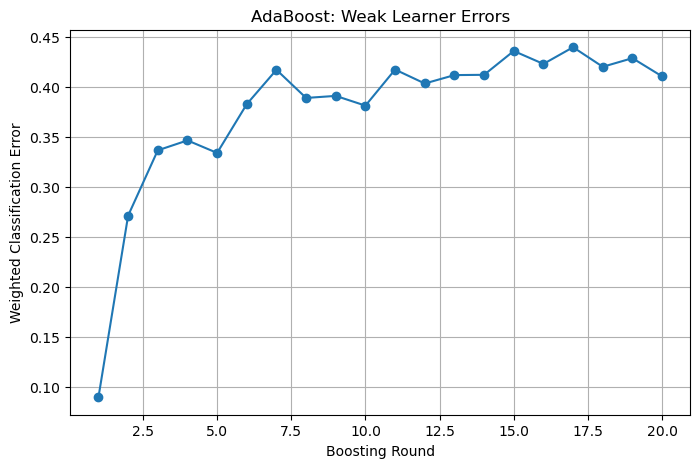

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(model.errors) + 1),
    model.errors,
    marker="o"
)

plt.xlabel("Boosting Round")
plt.ylabel("Weighted Classification Error")
plt.title("AdaBoost: Weak Learner Errors")
plt.grid(True)

plt.show()

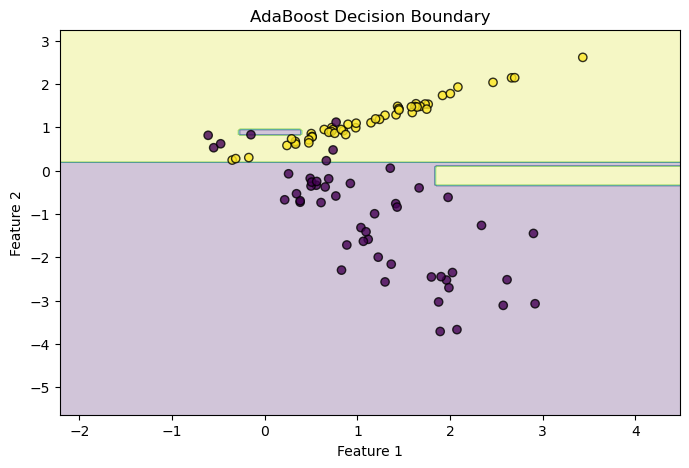

In [8]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5))

plt.contourf(xx, yy, Z, alpha=0.25)
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    edgecolors="black",
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("AdaBoost Decision Boundary")
plt.show()

In [9]:
sklearn_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=20,
    random_state=42
)

# Scikit-Learn expects class labels; {-1, +1} is supported.
sklearn_model.fit(X_train, y_train)

sklearn_pred = sklearn_model.predict(X_test)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "From Scratch": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    ],
    "Scikit-Learn": [
        accuracy_score(y_test, sklearn_pred),
        precision_score(y_test, sklearn_pred, pos_label=1, zero_division=0),
        recall_score(y_test, sklearn_pred, pos_label=1, zero_division=0),
        f1_score(y_test, sklearn_pred, pos_label=1, zero_division=0)
    ]
})

comparison

,Metric,From Scratch,Scikit-Learn
0,Accuracy,0.940000,0.930000
1,Precision,0.892857,0.877193
2,Recall,1.000000,1.000000
3,F1 Score,0.943396,0.934579
